(rs_portfolio:title)=
# Robust Satisficing for Portfolio Optimization

In this example, we consider the portfolio optimization problem introduced in {cite:ps}`Long_Sim_Zhou2023robust`, where the decision-maker invests in $m$ risky assets and the portfolio risk is evaluated using the empirical distribution $\hat{\mathbb{P}}_n$, constructed from historical data $\left(\hat{z}_1, ..., \hat{z}_n\right)$. Here, the problem is solved as a robust satisficing model

\begin{align}
\min~&k_0 + wk_1 \\
\text{s.t. }& \mathbb{E}_{\mathbb{P}}\left[\tilde{\pmb{z}}^{\top}\pmb{x}\right] \geq \tau -  k_0 \Delta_W(\mathbb{P}, \hat{\mathbb{P}}_n) &&\forall \mathbb{P}\in\mathcal{P}_0(\mathcal{Z})\\
&\alpha + \frac{1}{\epsilon}\mathbb{E}_{\mathbb{P}}\left[\max\left\{-\tilde{\pmb{x}}^{\top}\pmb{x} - \alpha, 0\right\}\right] \leq \beta + k_1 \Delta_W(\mathbb{P}, \hat{\mathbb{P}}_n) &&\forall\mathbb{P}\in\mathcal{P}_0(\mathcal{Z})\\
&\sum\limits_{i=1}^mx_i = 1 \\
&\pmb{x}\in\mathbb{R}_+^m, ~\alpha\in\mathbb{R},~k_0\in\mathbb{R},~k_1\in\mathbb{R},
\end{align}

for some target $\tau$ of the expected return, and some target $\beta$ of the $1-\epsilon$ conditional value at risk (CVaR). Here, $\mathcal{P}_0(\mathcal{Z})$ represents the set of all distributions for the
multivariate random variable that has support $\mathcal{Z}=\mathbb{R}^m$, and the expression $\Delta_W(\mathbb{P}, \hat{\mathbb{P}}_n)$ indicates the Wasserstein distance with one-norm between the distribution $\mathbb{P}$ and empirical distribution $\hat{\mathbb{P}}_n$. In the subsequent numerical studies, parameters of the models are configured as

- The number of assets is $m=10$;
- The penalty parameter $w=10$;
- The CVaR confidence level $1-\epsilon=0.95$;
- The target of the expected return is $\tau=0.125$;
- The target of the CVaR term is $\beta=0.05$.

In [1]:
m = 10
w = 10
epsilon = 0.05
tau = 0.125
beta = 0.05

Similar to {cite:ps}`Mohajerin_Kuhn2018data`, the random return $\tilde{z}_i$ of each asset is decomposable into a systematic risk factor $\psi \sim N(0, 5\%)$ common to all assets and an idiosyncratic risk factor $\zeta_i\in N(i\times 3\%, i\times 2.5\%)$ specific to asset $i$. The empirical distribution of the random returns $\tilde{\pmb{z}}$ is then represented by a randomly generated sample dataset using the `norm_return()` function defined below.

In [2]:
import numpy as np

def norm_return(n, m):

    i = np.arange(1, m+1)
    psi = 0.05 * np.random.normal(size=(n, m))
    zeta = 0.02*i + 0.03*i*np.random.normal(size=(n, m))
    zhat = psi + zeta

    return zhat

In the following code segment, a empirical dataset named `zhat` consisting of $n=300$ records for $m=10$ assets is generated.

In [3]:
np.random.seed(10)

n, m = 300, 10
zhat = norm_return(n, m)

## Equivalent Deterministic Problem

According to **Theorem 9** of {cite:ps}`Long_Sim_Zhou2023robust`, the robust satisficing model can be reformulated as the following deterministic linear optimization problem:

```{math}
\begin{aligned}
\min~&\|\pmb{x}\|_{\infty} \\
\text{s.t. }&\frac{1}{n}\sum\limits_{s=1}^ny_{1s} \geq \tau \\
&y_{1s} \leq \hat{\pmb{z}}_s^{\top}\pmb{x} &&\forall s\in [n]\\
&\alpha + \frac{1}{n\epsilon}\sum\limits_{s\in[n]}y_{2s} \leq \beta \\
&y_{2s} \geq -\hat{\pmb{z}}_s^{\top}\pmb{x} - \alpha &&\forall s \in [n]\\
&y_{2s} \geq 0 &&\forall s \in [n] \\
&\sum\limits_{i=1}^mx_i = 1 \\
&\pmb{x}_+^m,~\alpha\in\mathbb{R},~\pmb{y}\in\mathbb{R}^{2\times n}.
\end{aligned}
```

In [4]:
from rsome import ro
import rsome as rso

model = ro.Model()

x = model.dvar(m)
alpha = model.dvar()
y1 = model.dvar(n)
y2 = model.dvar(n)

model.min(rso.norm(x, 'inf'))
model.st((1/n) * y1.sum() >= tau, y1 <= zhat@x)
model.st(alpha + (1/n/epsilon)*y2.sum() <= beta)
model.st(y2 >= 0)
for s in range(n):
    model.st(y1[s] <= x@zhat[s],
             y2[s] >= -x@zhat[s] - alpha)
model.st(x.sum() == 1, x >= 0)

model.solve()

Being solved by the Scipy LP solver...
Solution status: 0
Running time: 0.0093s


The optimal solution in terms of the investment decision is given below.

In [5]:
print(x.get())

[0.         0.01019506 0.12372562 0.12372562 0.12372562 0.12372562
 0.12372562 0.12372562 0.12372562 0.12372562]


## Scenario-Wise Robust Optimization Problem

The robust satisficing model above is also equivalent to the following scenario-wise optimization problem:

```{math}
\begin{aligned}
\min~&k_0 + wk_1 \\
\text{s.t. }&\frac{1}{n}\sum\limits_{s=1}^nv_{1s} \geq \tau \\
&\alpha + \frac{1}{n\epsilon}\sum\limits_{s\in[n]}v_{2s} \leq \beta \\
&v_{1s} \leq \pmb{z}^{\top}\pmb{x} + k_0 u &&\forall (\pmb{z}, u)\in\mathcal{Z}_s,~\forall s\in[n] \\
&v_{2s} \geq \frac{1}{\epsilon}\left(-\pmb{z}^{\top}\pmb{x} - \alpha\right) - k_1u &&\forall (\pmb{z}, u)\in\mathcal{Z}_s,~ \forall s \in [n] \\
&v_{2s} \geq -k_1 u &&\forall (\pmb{z}, u)\in\mathcal{Z}_s, ~\forall s \in [n] \\
&\sum\limits_{i=1}^mx_i = 1 \\
&\pmb{x}_+^m,~\alpha\in\mathbb{R},~k_0 \in \mathbb{R}, ~k_1 \in \mathbb{R}, ~\pmb{v}\in\mathbb{R}^{2\times n},
\end{aligned}
```

with the support $\mathcal{Z}_s = \left\{(\pmb{z}, u): \|\pmb{z} - \hat{\pmb{z}}_s\| \leq u\right\}$ for each sample $s$. This robust model is implemented by the code segment below.

In [6]:
from rsome import ro
import rsome as rso

model = ro.Model()

x = model.dvar(m)
alpha = model.dvar()
k0 = model.dvar()
k1 = model.dvar()
v1 = model.dvar(n)
v2 = model.dvar(n)

z = model.rvar(m)
u = model.rvar()

model.min(k0 + w*k1)
model.st(v1.sum() * (1/n) >= tau)
model.st(alpha + v2.sum() * (1/n) <= beta)
for s in range(n):
    uset = (rso.norm(z - zhat[s], 1) <= u)
    model.st(v1[s] <= z@x + k0*u,
             v2[s] >= (1/epsilon)*(-z@x-alpha) - k1*u,
             v2[s] >= -k1*u, forall=uset)
model.st(x >= 0, x.sum() == 1)
model.solve()

Being solved by the Scipy LP solver...
Solution status: 0
Running time: 0.6471s


The equivalent robust model yields the same optimal solution as the previous deterministic optimization problem. 

In [7]:
print(x.get())

[0.         0.01019506 0.12372562 0.12372562 0.12372562 0.12372562
 0.12372562 0.12372562 0.12372562 0.12372562]


## Distributionally Robust Model

Alternatively, the robust satisficing model can be directly formulated as an RSOME `dro` model. 

In [8]:
from rsome import dro
from rsome import E
import rsome as rso

model = dro.Model(n)

x = model.dvar(m)
alpha = model.dvar()
k0 = model.dvar()
k1 = model.dvar()

z = model.rvar(m)
u = model.rvar()
fset = model.ambiguity()
for s in range(n):
    fset[s].suppset(rso.norm(z-zhat[s], 1) <= u)
pr = model.p
fset.probset(pr == 1/n)

model.minsup(k0 + w*k1, forall=fset)
model.st(E(z@x) >= tau - E(k0*u))
model.st(alpha + (1/epsilon)*E(rso.maxof(-z@x-alpha, 0) - epsilon*k1*u) <= beta)
model.st(x >= 0, x.sum() == 1)

model.solve()

Being solved by the Scipy LP solver...
Solution status: 0
Running time: 0.6456s


Here, we use the scenario-wise ambiguity set proposed in {cite:ps}`Chen_Sim_Xiong_2020robust` to capture the Wasserstein distance, the same optimal solution can be obtained as follows.

In [9]:
print(x.get())

[-0.          0.01019506  0.12372562  0.12372562  0.12372562  0.12372562
  0.12372562  0.12372562  0.12372562  0.12372562]


## Performance of the Robust Satisficing Model

In this section, we will assess the performance in terms of the out-of-sample mean return and CVaR of the robust satisficing model under different target $\tau$. The out-of-sample CVaR is evaluated using the `out_cvar()` function defined below.

In [10]:
def out_cvar(rs, epsilon):

    n = len(rs)

    model = ro.Model()
    alpha = model.dvar()
    v = model.dvar(n)

    model.min(alpha + (1/n/epsilon) * v.sum())
    model.st(v >= 0, v >= -rs - alpha)

    model.solve(display=False)

    return model.get()

The robust satisficing model is also defined as the following `portfolio_rs()` function.

In [11]:
def portfolio_rs(zhat, beta, tau, epsilon):

    model = ro.Model()

    x = model.dvar(m)
    alpha = model.dvar()
    y1 = model.dvar(n)
    y2 = model.dvar(n)

    model.min(rso.norm(x, 'inf'))
    model.st((1/n) * y1.sum() >= tau, y1 <= zhat@x)
    model.st(alpha + (1/n/epsilon)*y2.sum() <= beta)
    model.st(y2 >= 0)
    for s in range(n):
        model.st(y1[s] <= x@zhat[s], y2[s] >= -x@zhat[s] - alpha)
    model.st(x.sum() == 1, x >= 0)

    model.solve(display=False)

    return x.get()

It is compared with a robust optimization model

```{math}
\begin{aligned}
\max~&\inf\limits_{\mathbb{P}\in\mathcal{P}_0(\mathcal{Z})}\mathbb{E}_{\mathbb{P}}\left[\tilde{\pmb{z}}^{\top}\pmb{x}\right] \\
\text{s.t. }&\alpha + \frac{1}{\epsilon}\mathbb{E}_{\mathbb{P}}\left[\max\left\{-\tilde{\pmb{x}}^{\top}\pmb{x} - \alpha, 0\right\}\right] \leq \beta &&\forall \mathbb{P}\in\mathcal{B}(r) \\
&\sum\limits_{i=1}^mx_i = 1 \\
&\pmb{x}\in\mathbb{R}_+^m, ~\alpha\in\mathbb{R},
\end{aligned}
```

where $\mathcal{B}(r)$ is a Wasserstein ambiguity set with the one-norm distance to be $r$. The robust optimization model is defined as the following `protfolio_ro()` function.

In [26]:
def portfolio_ro(zhat, d, beta, epsilon):

    if d == 0:
        d = 1e-6

    n, m = zhat.shape
    model = dro.Model(n)

    x = model.dvar(m)
    alpha = model.dvar()

    z = model.rvar(m)
    u = model.rvar()
    fset = model.ambiguity()
    for s in range(n):
        fset[s].suppset(rso.norm(z - zhat[s], 1) <= u)
    fset.exptset(E(u) <= d)
    pr = model.p
    fset.probset(pr == 1/n)

    model.maxinf(E(z@x), fset)
    model.st(alpha + (1/epsilon)*E(rso.maxof(-z@x-alpha, 0)) <= beta)
    model.st(x >= 0, x.sum() == 1)

    model.solve(display=False)

    return x.get()

We first run the robust optimization model `protfolio_ro()` as the Wasserstein distance parameter `r` is varying from $0$ to $0.02$. The out-of-sample performance interms of the mean and CVaR is calculated based on a randomly generated sample dataset with $10,000$ records. Besides, the in-sample average return of the solution yielded under `r=0.0` is defined to be `Tmax`, representing the maximum value of the target $\tau$. The in-sample average return of an equal-weighted portfolio is defined to be `Tmin`, representing the minimum value of $\tau$.

In [27]:
zout = norm_return(10000, m)

means_ro = []
cvars_ro = []
dmax = 0.0
r_values = np.linspace(0, 0.02, 12)
for r in r_values:
    xs = portfolio_ro(zhat, r, beta, epsilon)
    rs = zout@xs
    if r == 0:
        Tmax = (zhat@xs).mean()

    means_ro.append(rs.mean())
    cvars_ro.append(out_cvar(rs, epsilon))

Tmin = (zhat@(np.ones(m)/m)).mean()

The following code solves the robust satisficing model as the target $\tau$ changes between `Tmin` and `Tmax`, and out-of-sample mean and CVaR are also calculated to assess the performance of the robust satisficing decisions. 

In [28]:
tau_values = np.linspace(Tmin, Tmax, 15)
sols = np.zeros((len(tau_values), m))
means_rs = []
cvars_rs = []
for tau in tau_values:
    xs = portfolio_rs(zhat, beta, tau, epsilon)
    rs = zout@xs

    means_rs.append(rs.mean())
    cvars_rs.append(out_cvar(rs, epsilon))

The performance of the robust model and the satisficing model is shown in the following figure. Please refer to **Fig. 4** of {cite:ps}`Long_Sim_Zhou2023robust` for the similar results. 

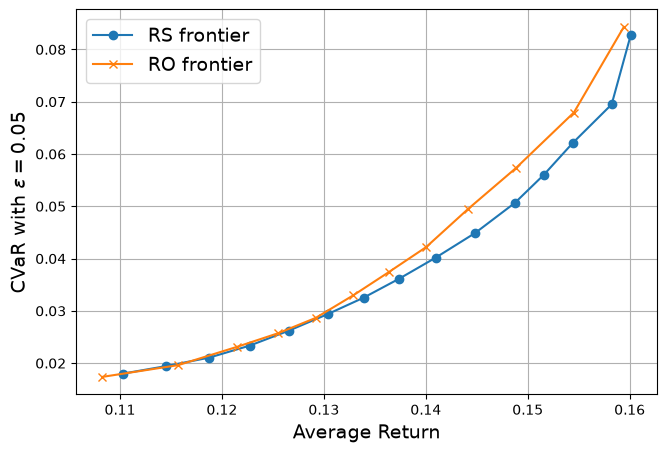

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7.5, 5))
plt.plot(means_rs, cvars_rs, marker='o', label='RS frontier')
plt.plot(means_ro, cvars_ro, marker='x', label='RO frontier')
plt.legend(fontsize=14)
plt.xlabel('Average Return', fontsize=14)
plt.ylabel(r'CVaR with $\epsilon={}$'.format(epsilon), fontsize=14)
plt.grid()
plt.show()

<br>
<br>

<font size="5">Reference</font>

```{bibliography}
:filter: docname in docnames
```